## Kattegat Ferry Services, North/South Passages, and a Later Southern Route (Flag 7)

### Dataset Overview
This derived case contains AIS-like trajectories for the two Section 9.3 ferry services, M/F Anholt and Stena Nautica, together with vessel attributes, landmark locations, and representative annual-passage weights. The named services and the 300/900 north/south annual movement pattern follow Section 9.3 and Figures 9-13–9-15 of risk_to_ship_traffic.pdf. The later, more southerly Stena Nautica route is included for the third insight.

The notebook exposes a primary table and a supporting table (`ferry_vessels.csv`).

Goal: To detect and investigate movement patterns of ferry traffic with given trajectories of ferry vessels in this area.

Role: Maritime traffic analyst


Category: Kattegat ferry traffic and route change

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "ferry_vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which distinct ferry services can be identified from the vessel identities, recurring trajectories, and supplied landmark locations?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

ferry_name     from            to            
Stena Nautica  Grenaa          Varberg           6
               Varberg         Grenaa            6
M/F Anholt     Anholt Harbour  Grenaa            4
               Grenaa          Anholt Harbour    4


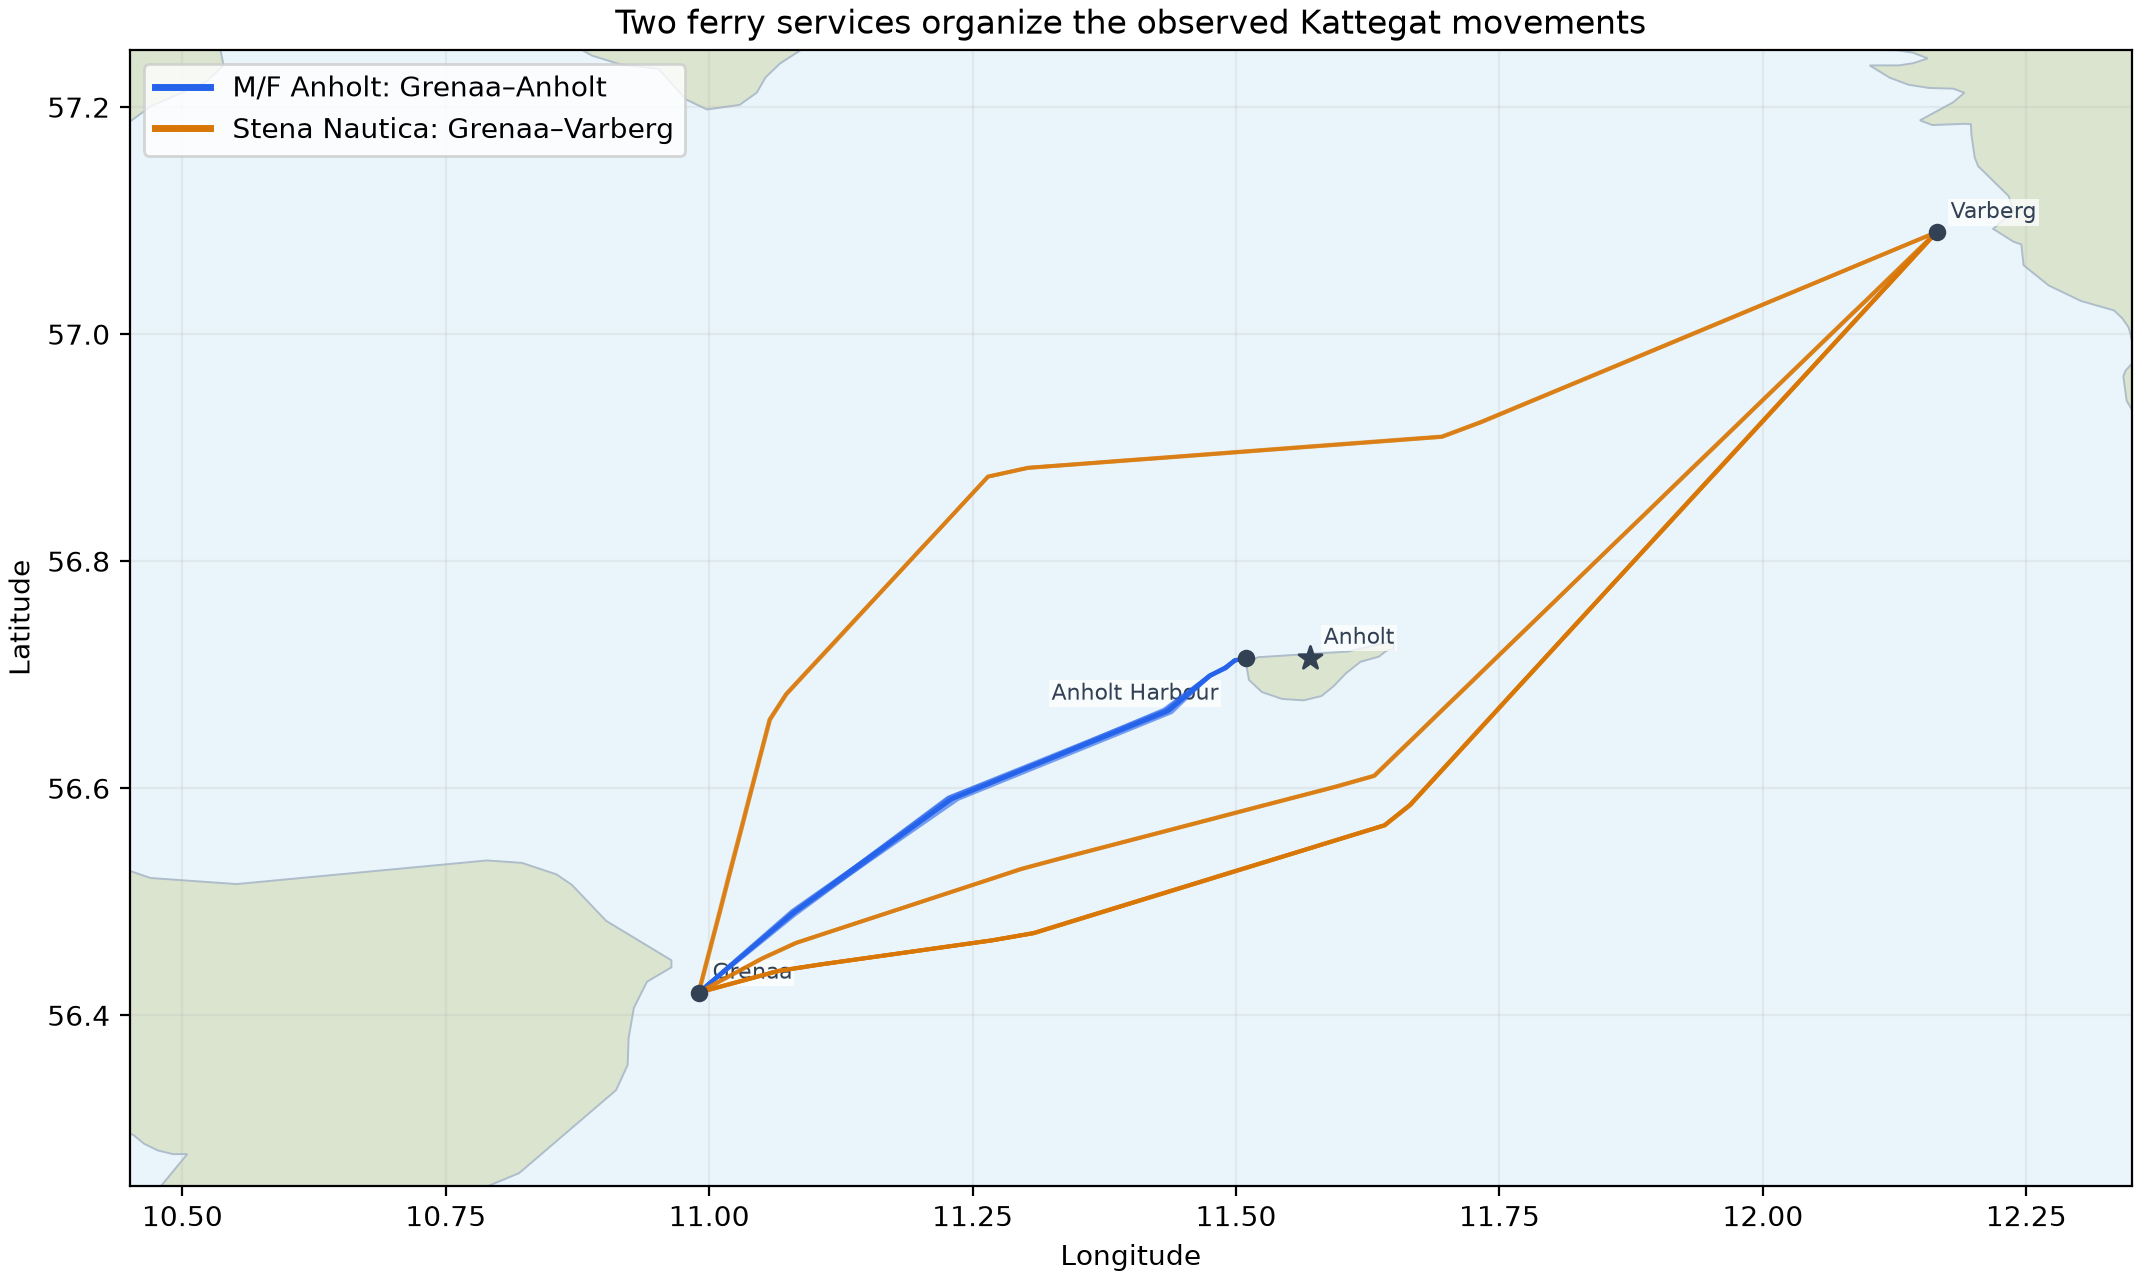

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
points = pd.read_csv(dataset_path)
points['timestamp'] = pd.to_datetime(points['timestamp'])
landmarks = pd.read_csv(Path(dataset_path).with_name('landmarks.csv')).set_index('landmark_id')
ferries = pd.read_csv(user_dataset_path)
ports = landmarks.loc[['grenaa', 'anholt_port', 'varberg']]
visits = []
for trip, group in points.groupby('trajectory_id'):
    ordered = group.sort_values('timestamp')
    ends = []
    for row in [ordered.iloc[0], ordered.iloc[-1]]:
        # A local distance approximation is sufficient for nearest-reference
        # assignment; Grenaa and Varberg are offshore approach references.
        d2 = ((ports.lon-row.lon)*np.cos(np.radians(row.lat)))**2 + (ports.lat-row.lat)**2
        ends.append(ports.loc[d2.idxmin(), 'landmark_name'])
    visits.append({'trajectory_id': trip, 'vessel_id': ordered.vessel_id.iloc[0],
                   'departure': ordered.timestamp.iloc[0], 'from': ends[0], 'to': ends[1]})
service_endpoints = pd.DataFrame(visits).merge(ferries[['vessel_id','ferry_name']], on='vessel_id', validate='many_to_one')
print(service_endpoints[['ferry_name','from','to']].value_counts().to_string())

from IPython.display import Image, display
display(Image(filename='visualizations/ferry_services_map.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "ferry_service_identification",
  "insight": "Two ferry services operate in the area: M/F Anholt runs between Grenaa and Anholt, while Stena Nautica runs between Grenaa and Varberg.",
  "insight_value": {
    "ferries": [
      {
        "name": "M/F Anholt",
        "service": "Grenaa–Anholt"
      },
      {
        "name": "Stena Nautica",
        "service": "Grenaa–Varberg"
      }
    ]
  },
  "plot": {
    "plot_type": "geographic_service_map",
    "title": "Two Kattegat Ferry Services",
    "file": "visualizations/ferry_services_map.png",
    "description": "The two services form distinct recurrent movement patterns around Grenaa, Anholt, and Varberg."
  },
  "question": "Which distinct ferry services can be identified from the vessel identities, recurring trajectories, and supplied landmark locations?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\npoints['timestamp'] = pd.to_datetime(points['timestamp'])\nlandmarks = pd.read_csv(Path(dataset_path).with_name('landmarks.csv')).set_index('landmark_id')\nferries = pd.read_csv(user_dataset_path)\nports = landmarks.loc[['grenaa', 'anholt_port', 'varberg']]\nvisits = []\nfor trip, group in points.groupby('trajectory_id'):\n    ordered = group.sort_values('timestamp')\n    ends = []\n    for row in [ordered.iloc[0], ordered.iloc[-1]]:\n        # A local distance approximation is sufficient for nearest-reference\n        # assignment; Grenaa and Varberg are offshore approach references.\n        d2 = ((ports.lon-row.lon)*np.cos(np.radians(row.lat)))**2 + (ports.lat-row.lat)**2\n        ends.append(ports.loc[d2.idxmin(), 'landmark_name'])\n    visits.append({'trajectory_id': trip, 'vessel_id': ordered.vessel_id.iloc[0],\n                   'departure': ordered.timestamp.iloc[0], 'from': ends[0], 'to': ends[1]})\nservice_endpoints = pd.DataFrame(visits).merge(ferries[['vessel_id','ferry_name']], on='vessel_id', validate='many_to_one')\nprint(service_endpoints[['ferry_name','from','to']].value_counts().to_string())\n",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "landmark_location",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How do the annualized Grenaa–Varberg ferry movements compare between passages north and south of Anholt?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

Observed representative passages: {'south': 9, 'north': 3}
Represented annual movements: {'north': 300, 'south': 900}


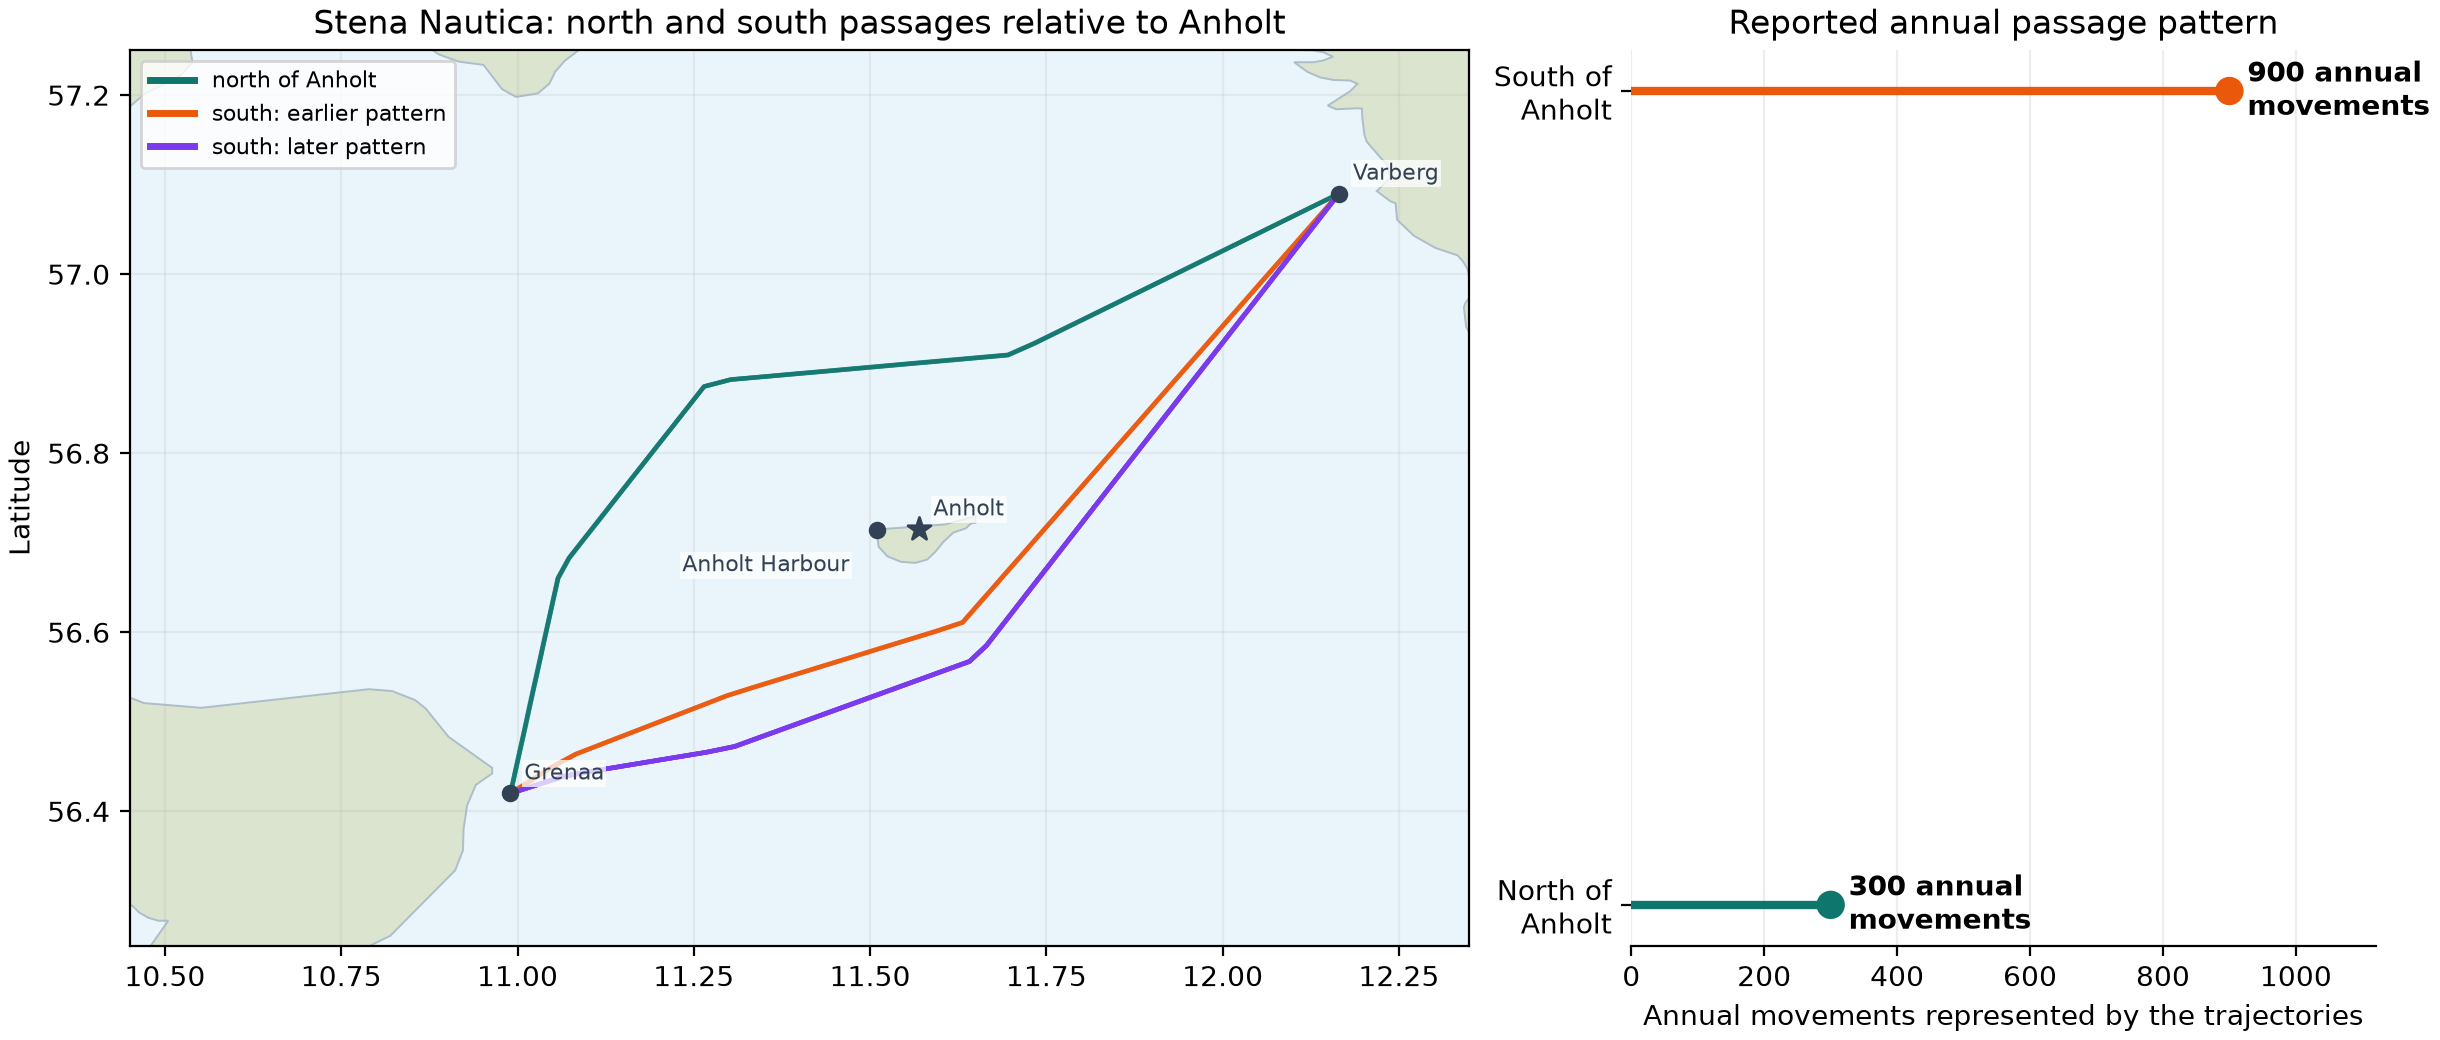

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
points = pd.read_csv(dataset_path)
points['timestamp'] = pd.to_datetime(points['timestamp'])
landmarks = pd.read_csv(Path(dataset_path).with_name('landmarks.csv')).set_index('landmark_id')
weights = pd.read_csv(Path(dataset_path).with_name('trip_weights.csv'))
stena = points[points.vessel_id.eq('ferry_stena_nautica')]
anholt = landmarks.loc['anholt']
mid = stena[stena.lon.between(anholt.lon-0.12, anholt.lon+0.08)]
sides = mid.groupby('trajectory_id').lat.mean().gt(anholt.lat).map({True:'north',False:'south'}).rename('side')
annual_movements = weights.merge(sides, on='trajectory_id', validate='one_to_one').groupby('side').represented_annual_movements.sum()
print('Observed representative passages:', sides.value_counts().to_dict())
print('Represented annual movements:', annual_movements.to_dict())

from IPython.display import Image, display
display(Image(filename='visualizations/stena_north_south_frequency.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_frequency_comparison",
  "insight": "The Grenaa–Varberg ferry represented by Stena Nautica has approximately 300 annual movements north of Anholt and 900 south of Anholt.",
  "insight_value": {
    "north_of_anholt": 300,
    "south_of_anholt": 900,
    "north_to_south_ratio": "1:3"
  },
  "plot": {
    "plot_type": "map_and_lollipop_comparison",
    "title": "Stena Nautica North/South Passage Pattern",
    "file": "visualizations/stena_north_south_frequency.png",
    "description": "The map separates Stena Nautica trajectories north and south of Anholt; each representative trajectory carries an annual-passage weight in trip_weights.csv."
  },
  "question": "How do the annualized Grenaa–Varberg ferry movements compare between passages north and south of Anholt?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\npoints['timestamp'] = pd.to_datetime(points['timestamp'])\nlandmarks = pd.read_csv(Path(dataset_path).with_name('landmarks.csv')).set_index('landmark_id')\nweights = pd.read_csv(Path(dataset_path).with_name('trip_weights.csv'))\nstena = points[points.vessel_id.eq('ferry_stena_nautica')]\nanholt = landmarks.loc['anholt']\nmid = stena[stena.lon.between(anholt.lon-0.12, anholt.lon+0.08)]\nsides = mid.groupby('trajectory_id').lat.mean().gt(anholt.lat).map({True:'north',False:'south'}).rename('side')\nannual_movements = weights.merge(sides, on='trajectory_id', validate='one_to_one').groupby('side').represented_annual_movements.sum()\nprint('Observed representative passages:', sides.value_counts().to_dict())\nprint('Represented annual movements:', annual_movements.to_dict())\n",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "landmark_location",
    "annual_movement_weight",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Does the Grenaa–Varberg ferry route south of Anholt change over time, and if so, how does its turning point shift after the change?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

   trajectory_id  period       lon       lat
stena_nautica_04 earlier 11.630309 56.610226
stena_nautica_05 earlier 11.629900 56.610107
stena_nautica_06 earlier 11.630342 56.609766
stena_nautica_07   later 11.650273 56.569964
stena_nautica_08   later 11.650220 56.570149
stena_nautica_09   later 11.650008 56.569933
stena_nautica_10   later 11.650124 56.569856
stena_nautica_11   later 11.649539 56.569995
stena_nautica_12   later 11.650374 56.569771
Mean dominant turning vertex shifts south by 4.458 km.


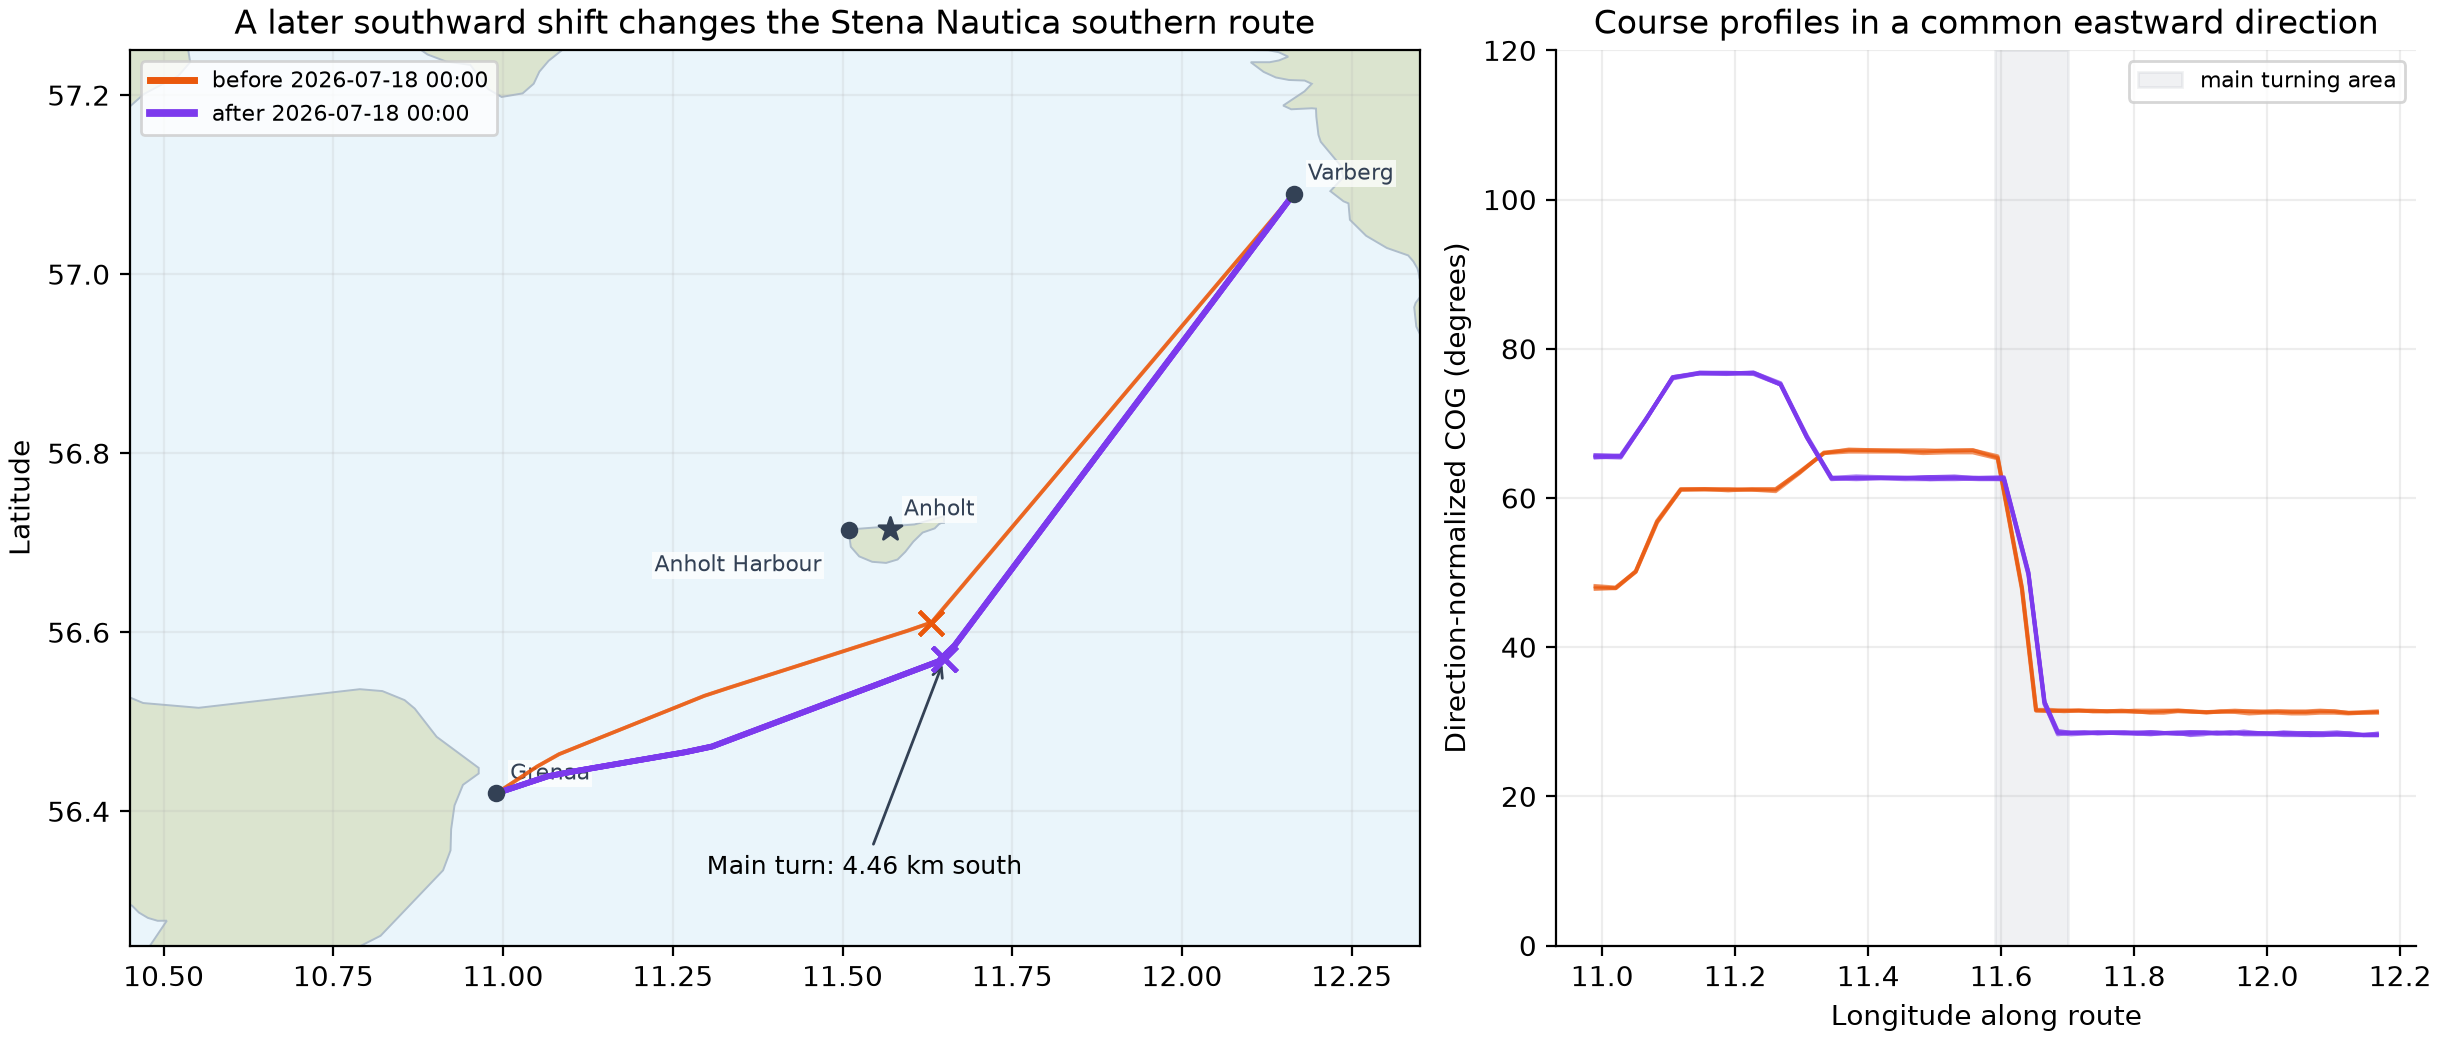

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path
points = pd.read_csv(dataset_path)
points['timestamp'] = pd.to_datetime(points['timestamp'])
landmarks = pd.read_csv(Path(dataset_path).with_name('landmarks.csv')).set_index('landmark_id')
def fit_turns(points):
    """Estimate the dominant southern turning vertex from east-oriented arms."""
    frame=pd.DataFrame(points);result=[]
    for trip,g in frame[frame.vessel_id.eq('ferry_stena_nautica')].groupby('trajectory_id'):
        if g[g.lon.between(11.45,11.65)].lat.mean()>float(landmarks.loc['anholt', 'lat']):continue
        g=g.sort_values('point_index')
        if g.lon.iloc[0]>g.lon.iloc[-1]:g=g.iloc[::-1]
        x,y=g.lon.to_numpy(),g.lat.to_numpy()
        # Circular COG change locates the turn; fit GPS arms beyond its sampled
        # smoothing window to estimate the physical vertex.
        cog=g.cog.to_numpy();angle=np.abs((cog[2:]-cog[:-2]+180)%360-180)
        eligible=np.flatnonzero((x[1:-1]>11.15)&(x[1:-1]<11.9));i=eligible[np.argmax(angle[eligible])]+1
        left=np.polyfit(x[i-5:i-1],y[i-5:i-1],1);right=np.polyfit(x[i+2:i+6],y[i+2:i+6],1)
        lon=(right[1]-left[1])/(left[0]-right[0]);lat=np.polyval(left,lon)
        result.append(dict(trajectory_id=trip,period='later' if pd.to_datetime(g.timestamp).min()>=pd.Timestamp('2026-07-18') else 'earlier',lon=float(lon),lat=float(lat)))
    return pd.DataFrame(result)

turns = fit_turns(points)
mean_turn_lat = turns.groupby('period').lat.mean()
# North-south displacement on the same spherical Earth as the motion checks.
turn_shift_south_km = float(np.radians(mean_turn_lat['earlier']-mean_turn_lat['later'])*6371.0088)
print(turns.to_string(index=False))
print(f'Mean dominant turning vertex shifts south by {turn_shift_south_km:.3f} km.')

from IPython.display import Image, display
display(Image(filename='visualizations/post_change_diversion.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal_route_change",
  "insight": "The central turning point of Stena Nautica's Grenaa–Varberg passages south of Anholt shifts southward.",
  "insight_value": {
    "change_time": "2026-07-18 00:00",
    "service": "Stena Nautica Grenaa–Varberg",
    "turn_shift_south_km": 4.5,
    "measurement": "Mean latitude displacement of fitted dominant turning vertices; circular COG change locates each bend, and adjoining GPS arms locate its vertex."
  },
  "plot": {
    "plot_type": "temporal_route_comparison",
    "title": "Later Southward Shift in the Stena Nautica Southern Route",
    "file": "visualizations/post_change_diversion.png",
    "description": "Earlier and later southern routes, fitted main turning vertices, and COG profiles normalized to eastward travel. North-south vertex displacement is about 4.5 km."
  },
  "question": "Does the Grenaa–Varberg ferry route south of Anholt change over time, and if so, how does its turning point shift after the change?",
  "code": "import pandas as pd\nimport numpy as np\nfrom pathlib import Path\npoints = pd.read_csv(dataset_path)\npoints['timestamp'] = pd.to_datetime(points['timestamp'])\nlandmarks = pd.read_csv(Path(dataset_path).with_name('landmarks.csv')).set_index('landmark_id')\ndef fit_turns(points):\n    \"\"\"Estimate the dominant southern turning vertex from east-oriented arms.\"\"\"\n    frame=pd.DataFrame(points);result=[]\n    for trip,g in frame[frame.vessel_id.eq('ferry_stena_nautica')].groupby('trajectory_id'):\n        if g[g.lon.between(11.45,11.65)].lat.mean()>float(landmarks.loc['anholt', 'lat']):continue\n        g=g.sort_values('point_index')\n        if g.lon.iloc[0]>g.lon.iloc[-1]:g=g.iloc[::-1]\n        x,y=g.lon.to_numpy(),g.lat.to_numpy()\n        # Circular COG change locates the turn; fit GPS arms beyond its sampled\n        # smoothing window to estimate the physical vertex.\n        cog=g.cog.to_numpy();angle=np.abs((cog[2:]-cog[:-2]+180)%360-180)\n        eligible=np.flatnonzero((x[1:-1]>11.15)&(x[1:-1]<11.9));i=eligible[np.argmax(angle[eligible])]+1\n        left=np.polyfit(x[i-5:i-1],y[i-5:i-1],1);right=np.polyfit(x[i+2:i+6],y[i+2:i+6],1)\n        lon=(right[1]-left[1])/(left[0]-right[0]);lat=np.polyval(left,lon)\n        result.append(dict(trajectory_id=trip,period='later' if pd.to_datetime(g.timestamp).min()>=pd.Timestamp('2026-07-18') else 'earlier',lon=float(lon),lat=float(lat)))\n    return pd.DataFrame(result)\n\nturns = fit_turns(points)\nmean_turn_lat = turns.groupby('period').lat.mean()\n# North-south displacement on the same spherical Earth as the motion checks.\nturn_shift_south_km = float(np.radians(mean_turn_lat['earlier']-mean_turn_lat['later'])*6371.0088)\nprint(turns.to_string(index=False))\nprint(f'Mean dominant turning vertex shifts south by {turn_shift_south_km:.3f} km.')\n",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "landmark_location",
    "trajectory_timestamp",
    "course_over_ground"
  ]
}

### Summary of Findings (Flag 7)

Two recurrent ferry services connect Grenaa with Anholt and Varberg. Stena Nautica’s Grenaa–Varberg service is much more concentrated south of Anholt than north of it. In the later period, its south-of-Anholt route shifts to a second, more southerly turning pattern before continuing toward Varberg.